# Can the Baby GOAT Surpass the GOAT?
## 03 — Era-Adjusted Quarterback Performance

**Research question.** How did Tom Brady and Patrick Mahomes perform relative to the NFL environment of their respective seasons during their **first 131 regular-season starts**?

**Unit of comparison:** QB-attributed Expected Points Added (QB EPA) on eligible dropbacks (passes, sacks, and scrambles). The validated upstream pipeline restores historically tagged scrambles that were not flagged as dropbacks in the original PBP data.

This notebook is an **observational, descriptive comparison**, not an estimate of individual talent or causal QB impact. It does not assume the two quarterbacks played in identical team situations.

### Definitions

For quarterback $q$ in game $g$ of season $s$:

$$\text{Absolute QB EPA/DB}_{g}=\frac{\sum_{i\in g}\mathrm{QB\ EPA}_i}{N_g}$$

$$\text{Season-relative QB EPA/DB}_{g}=\text{Absolute QB EPA/DB}_g-\mu_s$$

where $N_g$ is the number of usable eligible dropbacks and $\mu_s$ is the NFL **dropback-weighted** mean QB EPA for season $s$.

We aggregate the first 131 starts by **total dropbacks**, not by taking an unweighted mean of game-level rates:

$$\text{Relative EPA/DB}_{131}=\frac{\sum_g(\mathrm{QB\ EPA}_g-N_g\mu_{s(g)})}{\sum_g N_g}$$

**Also included:** a season-standardized effect size, $(\mathrm{QB\ EPA/DB}-\mu_s)/\sigma_s$, where $\sigma_s$ is the **league play-level** standard deviation of QB EPA in that season. It is *not* a QB-rank z-score, a sampling z-statistic, or a QB percentile.

**Also included:** qualified-QB season percentiles computed against a season-specific cohort of eligible quarterbacks. These ranks describe full-season QB performance; when the scope differs from the selected 131 starts, it is explicitly flagged. Three-year relative EPA/DB remains a future extension.

## 1. Environment and validated sources

Run from the repository root with `jupyter lab`, or open the notebook from `notebooks/`. All inputs are **read-only** and generated by the validated processing scripts. Charts will be saved under `reports/figures/`.

Required inputs:

- `data/processed/nfl_season_dropback_baselines.parquet`
- `data/processed/qb_game_era_adjusted.parquet`
- `data/processed/qb_study_season_era_summary.parquet`
- `data/processed/qb_first_131_era_summary.parquet`

To rebuild inputs: run `scripts/build_nfl_epa_baselines.py` and then `scripts/build_qb_era_adjusted_stats.py`.

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import Markdown, display

# Team color palette from the established descriptive-analysis visuals.
COLORS = {
    "Tom Brady": "#002244",       # New England Patriots
    "Patrick Mahomes": "#E31837", # Kansas City Chiefs
}
ORDER = ["Tom Brady", "Patrick Mahomes"]
INK = "#17202A"
SUBTLE = "#64748B"
GRID = "#E2E8F0"

# Detect the repository root whether Jupyter starts in root/ or notebooks/.
search_roots = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (p for p in search_roots if (p / "data/processed/qb_game_era_adjusted.parquet").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Cannot locate data/processed/qb_game_era_adjusted.parquet. "
        "Open Jupyter from the project root and run the data pipeline first."
    )

PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

paths = {
    "games": PROCESSED / "qb_game_era_adjusted.parquet",
    "seasons": PROCESSED / "qb_study_season_era_summary.parquet",
    "career": PROCESSED / "qb_first_131_era_summary.parquet",
    "league": PROCESSED / "nfl_season_dropback_baselines.parquet",
}
missing_files = [str(p) for p in paths.values() if not p.is_file()]
if missing_files:
    raise FileNotFoundError("Missing validated inputs:\n" + "\n".join(missing_files))

games = pl.read_parquet(paths["games"])
seasons = pl.read_parquet(paths["seasons"])
career = pl.read_parquet(paths["career"])
league = pl.read_parquet(paths["league"])

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "axes.edgecolor": "#CBD5E1",
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": SUBTLE,
    "ytick.color": SUBTLE,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})

print(f"Project: {ROOT}")
print(f"Games: {games.height} | Study-season rows: {seasons.height} | "
      f"Career rows: {career.height} | League seasons: {league.height}")

Project: /home/lucas/2110/mahomes-brady
Games: 262 | Study-season rows: 20 | Career rows: 2 | League seasons: 20


## 2. Quality gates — fail before interpretation

These checks verify the research sample, unique keys, denominators, baseline coverage, and reconciliation between game and career totals. **Do not remove a failing assertion simply to display the figures.** Check the upstream processing if anything changes.

In [14]:
REQUIRED_GAMES = {
    "player_id", "player_name", "game_id", "start_no", "season",
    "usable_dropbacks", "qb_epa_sum", "qb_epa_per_dropback",
    "relative_qb_epa_total", "relative_qb_epa_per_dropback",
    "league_qb_epa_per_dropback", "qb_epa_success_rate",
    "relative_qb_epa_success_rate_pp",
}
REQUIRED_SEASONS = {
    "player_id", "player_name", "season", "starts", "usable_dropbacks",
    "qb_epa_per_dropback", "relative_qb_epa_per_dropback",
}
REQUIRED_CAREER = {
    "player_id", "player_name", "starts", "usable_dropbacks",
    "qb_epa_sum", "relative_qb_epa_total", "qb_epa_per_dropback",
    "relative_qb_epa_per_dropback", "expected_league_epa_per_dropback",
    "relative_qb_epa_success_rate_pp",
}
REQUIRED_LEAGUE = {
    "season", "baseline_scope", "usable_dropbacks",
    "league_qb_epa_per_dropback", "league_qb_epa_std",
}
for name, data, required in [
    ("games", games, REQUIRED_GAMES),
    ("study seasons", seasons, REQUIRED_SEASONS),
    ("career", career, REQUIRED_CAREER),
    ("league", league, REQUIRED_LEAGUE),
]:
    missing_cols = required - set(data.columns)
    assert not missing_cols, f"{name}: missing columns {sorted(missing_cols)}"

assert games.height == 262, "Expected exactly 262 starts"
assert career.height == 2, "Expected two quarterbacks"
assert league.height == 20, "Expected 20 NFL season baselines"
assert games.select(pl.struct("player_id", "game_id").n_unique()).item() == 262
assert league["season"].n_unique() == 20
assert sorted(games["season"].unique().to_list()) == sorted(league["season"].to_list())
assert set(games["player_name"].unique().to_list()) == set(ORDER)
assert not games.filter(pl.col("usable_dropbacks") <= 0).height
assert not league.filter(pl.col("league_qb_epa_std") <= 0).height

for player in ORDER:
    segment = games.filter(pl.col("player_name") == player).sort("start_no")
    assert segment.height == 131, f"{player}: expected 131 starts"
    assert segment["start_no"].to_list() == list(range(1, 132))
    row = career.filter(pl.col("player_name") == player).row(0, named=True)
    assert row["starts"] == 131
    assert int(segment["usable_dropbacks"].sum()) == int(row["usable_dropbacks"])
    assert np.isclose(float(segment["qb_epa_sum"].sum()), float(row["qb_epa_sum"]), atol=1e-6)
    assert np.isclose(float(segment["relative_qb_epa_total"].sum()),
                      float(row["relative_qb_epa_total"]), atol=1e-6)
    observed = float(row["relative_qb_epa_total"]) / float(row["usable_dropbacks"])
    assert np.isclose(observed, float(row["relative_qb_epa_per_dropback"]), atol=1e-10)

# All 2026 NFL context is explicitly partial, ending with the study date.
assert league.filter(pl.col("season") == 2026)["baseline_scope"].item() == "through_study_date"
assert league.filter(pl.col("season") != 2026).filter(
    pl.col("baseline_scope") != "full_regular_season"
).height == 0

print("PASS: 262 unique starts, 131 per QB, 20 matching baselines, valid denominators, reconciled career totals.")

PASS: 262 unique starts, 131 per QB, 20 matching baselines, valid denominators, reconciled career totals.


## 3. Figure 1 — What was the league environment?

This figure shows the **dropback-weighted NFL average** for each study season, not the performance of either quarterback. The two panels deliberately separate eras instead of drawing an artificial line across the missing 2011–2016 period.

**Interpretation prompts:** Which seasons had the highest/lowest league averages? Did the average rise monotonically over time? How should we treat the provisional 2026 baseline?

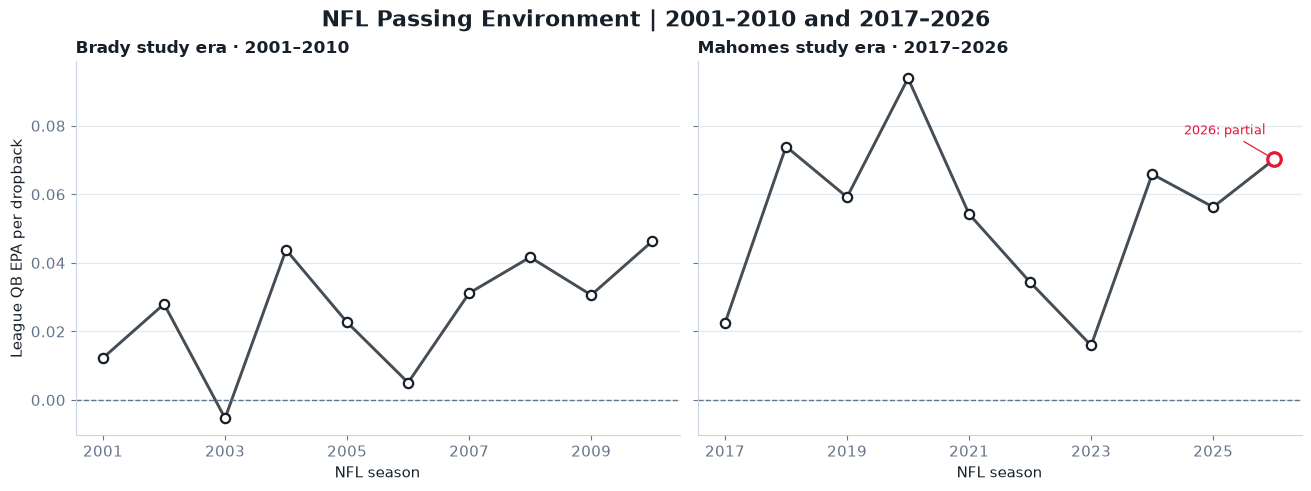

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True, layout="constrained")
for ax, years, subtitle in zip(
    axs,
    [range(2001, 2011), range(2017, 2027)],
    ["Brady study era · 2001–2010", "Mahomes study era · 2017–2026"],
):
    table = league.filter(pl.col("season").is_in(list(years))).sort("season")
    x = np.asarray(table["season"].to_list(), dtype=int)
    y = np.asarray(table["league_qb_epa_per_dropback"].to_list(), dtype=float)
    ax.plot(x, y, color=INK, linewidth=2.1, alpha=0.8, zorder=2)
    ax.scatter(x[:-1], y[:-1], s=45, facecolor="white", edgecolor=INK,
               linewidth=1.6, zorder=3)
    # Plot the final year explicitly; 2026 uses a hollow marker and a note.
    if x[-1] == 2026:
        ax.scatter([x[-1]], [y[-1]], s=95, facecolor="white",
                   edgecolor=COLORS["Patrick Mahomes"], linewidth=2.3, zorder=4)
        ax.annotate("2026: partial", xy=(x[-1], y[-1]), xytext=(-65, 18),
                    textcoords="offset points", fontsize=9, color=COLORS["Patrick Mahomes"],
                    arrowprops=dict(arrowstyle="-", color=COLORS["Patrick Mahomes"], lw=0.9))
    else:
        ax.scatter([x[-1]], [y[-1]], s=45, facecolor="white", edgecolor=INK,
                   linewidth=1.6, zorder=3)
    ax.axhline(0, color=SUBTLE, linewidth=1, linestyle="--")
    ax.set_xticks(x[::2])
    ax.set_title(subtitle, loc="left", fontsize=12, weight="semibold")
    ax.grid(axis="y", color=GRID, linewidth=0.9)
    ax.spines[["right", "top"]].set_visible(False)
    ax.set_xlabel("NFL season")
axs[0].set_ylabel("League QB EPA per dropback")
fig.suptitle("NFL Passing Environment | 2001–2010 and 2017–2026",
             fontsize=16, weight="bold")
fig.savefig(FIGURES / "04_nfl_era_baselines.png", dpi=220, bbox_inches="tight")
plt.show()

## 4. Figure 2 — The first 131 starts: absolute vs season-relative EPA

Every headline number is **dropback-weighted**. The expected NFL value for each QB is itself weighted according to *that QB's distribution of dropbacks across seasons*. It is generally not identical to the unweighted average of league season means.

The colored mark is observed QB EPA/DB, the gray mark is the matching league expectation, and the difference between them is **season-relative EPA/DB**. No inference about individual talent follows from these descriptive differences alone.

| Quarterback | Dropbacks | Absolute QB EPA/DB | Era-matched NFL EPA/DB | Relative QB EPA/DB | Relative success rate (pp) |
|:--|--:|--:|--:|--:|--:|
| Tom Brady | 4,607 | +0.1761 | +0.0220 | +0.1542 | +4.23 |
| Patrick Mahomes | 5,381 | +0.2486 | +0.0563 | +0.1923 | +5.86 |

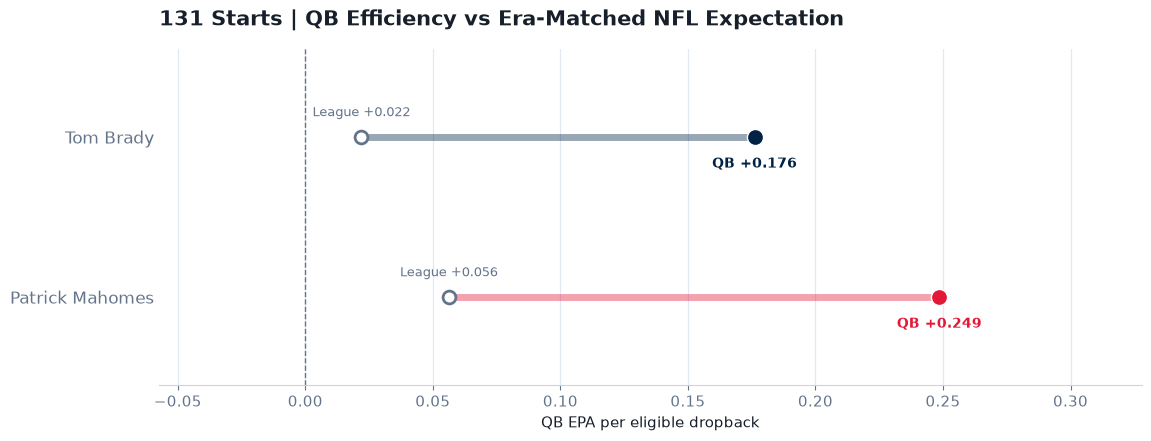

Higher observed era-relative QB EPA/DB: Patrick Mahomes (difference: +0.0381 EPA/DB).
This is a descriptive difference, not a QB-only causal effect or significance test.


In [16]:
rows = {r["player_name"]: r for r in career.to_dicts()}
lines = [
    "| Quarterback | Dropbacks | Absolute QB EPA/DB | Era-matched NFL EPA/DB | Relative QB EPA/DB | Relative success rate (pp) |",
    "|:--|--:|--:|--:|--:|--:|",
]
for player in ORDER:
    r = rows[player]
    lines.append(
        f"| {player} | {int(r['usable_dropbacks']):,} | "
        f"{r['qb_epa_per_dropback']:+.4f} | "
        f"{r['expected_league_epa_per_dropback']:+.4f} | "
        f"{r['relative_qb_epa_per_dropback']:+.4f} | "
        f"{r['relative_qb_epa_success_rate_pp']:+.2f} |"
    )
display(Markdown("\n".join(lines)))

values = [
    float(rows[p][k])
    for p in ORDER
    for k in ["qb_epa_per_dropback", "expected_league_epa_per_dropback"]
]
lo, hi = min(values), max(values)
span = max(hi - lo, 0.08)
fig, ax = plt.subplots(figsize=(11.4, 4.3), layout="constrained")
for i, player in enumerate(ORDER):
    r = rows[player]
    qb = float(r["qb_epa_per_dropback"])
    baseline = float(r["expected_league_epa_per_dropback"])
    color = COLORS[player]
    y = len(ORDER) - i
    ax.plot([baseline, qb], [y, y], color=color, alpha=0.40, linewidth=5,
            solid_capstyle="round", zorder=1)
    ax.scatter([baseline], [y], s=85, facecolor="white", edgecolor=SUBTLE,
               linewidth=2, zorder=3)
    ax.scatter([qb], [y], s=135, facecolor=color, edgecolor="white",
               linewidth=1, zorder=4)
    ax.annotate(f"League {baseline:+.3f}", (baseline, y), xytext=(0, 15),
                textcoords="offset points", ha="center", fontsize=9, color=SUBTLE)
    ax.annotate(f"QB {qb:+.3f}", (qb, y), xytext=(0, -22),
                textcoords="offset points", ha="center", fontsize=10,
                color=color, weight="bold")
ax.axvline(0, color=SUBTLE, linestyle="--", linewidth=1)
ax.set_xlim(lo - 0.35 * span, hi + 0.35 * span)
ax.set_yticks([2, 1], ORDER)
ax.set_ylim(0.45, 2.55)
ax.grid(axis="x", color=GRID, linewidth=0.9)
ax.set_axisbelow(True)
ax.spines[["right", "top", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=12)
ax.set_xlabel("QB EPA per eligible dropback")
ax.set_title("131 Starts | QB Efficiency vs Era-Matched NFL Expectation",
             fontsize=15, weight="bold", loc="left", pad=17)
fig.savefig(FIGURES / "05_qb_vs_era_baseline_131.png", dpi=220, bbox_inches="tight")
plt.show()

leader = max(ORDER, key=lambda p: float(rows[p]["relative_qb_epa_per_dropback"]))
follower = next(p for p in ORDER if p != leader)
delta = float(rows[leader]["relative_qb_epa_per_dropback"]) - float(rows[follower]["relative_qb_epa_per_dropback"])
print(f"Higher observed era-relative QB EPA/DB: {leader} (difference: {delta:+.4f} EPA/DB).")
print("This is a descriptive difference, not a QB-only causal effect or significance test.")

## 5. Figure 3 — Which study seasons contributed to the result?

Season bars represent **only the starts selected within the first-131-start sample**, not the player's entire season. Therefore, a one-start season can be extreme without carrying much weight in the 131-start aggregate.

Key small-sample cases: Brady **2008 (1 start)**, Brady **2010 (4 starts)**, Mahomes **2017 (1 start)**, and Mahomes **2026 (5 starts, partial NFL baseline)**.

**Interpretation prompts:** Which stretches were above/below their contemporary league mean? Do unusually high/low bars have many dropbacks? How different is the 131-start result from any single season?

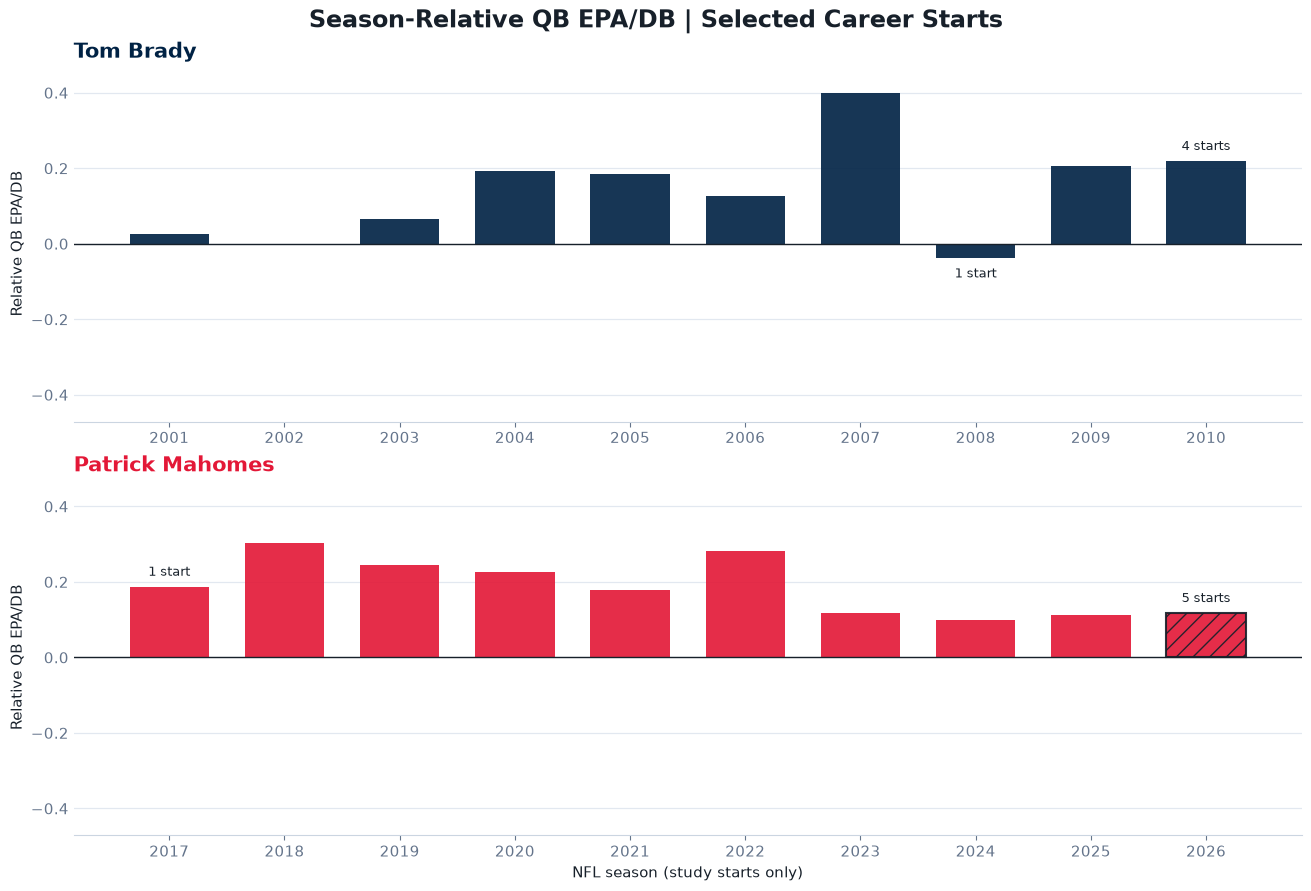

In [17]:
season_rows = seasons.to_dicts()
max_abs = max(abs(float(r["relative_qb_epa_per_dropback"])) for r in season_rows)
scale = max(max_abs * 1.18, 0.06)
fig, axs = plt.subplots(2, 1, figsize=(13, 8.8), sharey=True, layout="constrained")
for ax, player in zip(axs, ORDER):
    data = sorted((r for r in season_rows if r["player_name"] == player),
                  key=lambda r: int(r["season"]))
    xs = np.arange(len(data))
    ys = np.array([float(r["relative_qb_epa_per_dropback"]) for r in data])
    bars = ax.bar(xs, ys, width=0.69, color=COLORS[player], alpha=0.91)
    for bar, row, val in zip(bars, data, ys):
        if int(row["starts"]) <= 5:
            ax.annotate(f"{row['starts']} start{'s' if row['starts'] != 1 else ''}",
                        (bar.get_x() + bar.get_width()/2, val),
                        xytext=(0, 6 if val >= 0 else -7), textcoords="offset points",
                        ha="center", va="bottom" if val >= 0 else "top",
                        fontsize=9, color=INK)
        if int(row["season"]) == 2026:
            bar.set_edgecolor(INK)
            bar.set_linewidth(1.5)
            bar.set_hatch("//")
    ax.set_xticks(xs, [str(r["season"]) for r in data])
    ax.axhline(0, color=INK, linewidth=1)
    ax.set_ylim(-scale, scale)
    ax.set_ylabel("Relative QB EPA/DB")
    ax.set_title(player, loc="left", weight="bold", color=COLORS[player])
    ax.grid(axis="y", color=GRID, linewidth=0.9)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
axs[1].set_xlabel("NFL season (study starts only)")
fig.suptitle("Season-Relative QB EPA/DB | Selected Career Starts",
             fontsize=17, weight="bold")
fig.savefig(FIGURES / "06_season_relative_qb_epa.png", dpi=220, bbox_inches="tight")
plt.show()

## 6. Figure 4 — How did the era-relative advantage evolve over 131 starts?

The cumulative series uses **all dropbacks up to a given career start**:

$$\mathrm{Cumulative\ relative\ EPA/DB}(k)=\frac{\sum_{g=1}^{k}\mathrm{Relative\ EPA}_g}{\sum_{g=1}^{k} N_g}$$

A rolling **16-start** series shows local variation using the most recent 16 starts, also weighted by the number of dropbacks. This is a *game-window*, not a three-year season-relative benchmark. Early cumulative observations are unstable because they are based on small samples.

**Interpretation prompts:** Does the advantage persist throughout the sample? Are there different phases? Do high peaks or troughs depend on individual games or sustained runs?

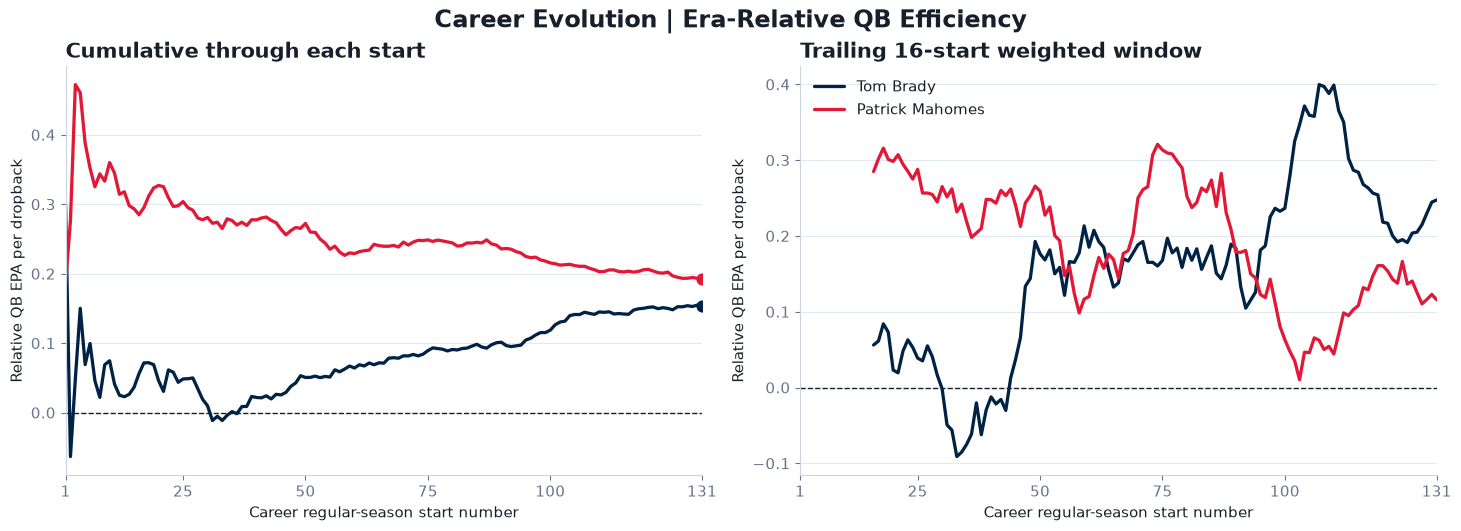

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(14.5, 5.2), sharex=True, layout="constrained")
WINDOW = 16
for player in ORDER:
    segment = games.filter(pl.col("player_name") == player).sort("start_no")
    start = np.asarray(segment["start_no"].to_list(), dtype=int)
    n = np.asarray(segment["usable_dropbacks"].to_list(), dtype=float)
    delta = np.asarray(segment["relative_qb_epa_total"].to_list(), dtype=float)
    cumulative = np.cumsum(delta) / np.cumsum(n)
    rolling = np.full(len(n), np.nan)
    for end in range(WINDOW - 1, len(n)):
        left = end - WINDOW + 1
        rolling[end] = delta[left:end+1].sum() / n[left:end+1].sum()
    for ax, series, name in [
        (axs[0], cumulative, "Cumulative"),
        (axs[1], rolling, "Rolling"),
    ]:
        ax.plot(start, series, color=COLORS[player], linewidth=2.35,
                label=player, solid_capstyle="round")
    axs[0].scatter([131], [cumulative[-1]], color=COLORS[player], s=60, zorder=3)

for ax in axs:
    ax.axhline(0, color=INK, linestyle="--", linewidth=1)
    ax.set_xlim(1, 131)
    ax.set_xticks([1, 25, 50, 75, 100, 131])
    ax.grid(axis="y", color=GRID)
    ax.set_xlabel("Career regular-season start number")
    ax.set_ylabel("Relative QB EPA per dropback")
    ax.spines[["top", "right"]].set_visible(False)
axs[0].set_title("Cumulative through each start", loc="left", weight="bold")
axs[1].set_title(f"Trailing {WINDOW}-start weighted window", loc="left", weight="bold")
axs[1].legend(loc="best", frameon=False)
fig.suptitle("Career Evolution | Era-Relative QB Efficiency", fontsize=17, weight="bold")
fig.savefig(FIGURES / "07_era_relative_career_evolution.png", dpi=220, bbox_inches="tight")
plt.show()

## 7. Figure 5 — Season-normalized EPA (dropback-SD units)

As an **additional descriptive lens**, divide the season-relative EPA/DB by the standard deviation of *individual dropback EPA values* across that NFL season:

$$z^{\mathrm{playSD}}_g=\frac{\mathrm{QB\ EPA/DB}_g-\mu_s}{\sigma_s^{\mathrm{dropback}}}$$

For the first 131 starts, we average game-level $z^{\mathrm{playSD}}$ values **weighted by usable dropbacks**. This accounts for changes in the *spread of play-level outcomes* across seasons.

**Do not interpret this as:** an NFL quarterback percentile, the number of standard deviations by which a QB beats other qualified QBs, or a z-test of statistical significance. Those require a separate **QB-level** reference distribution and qualification rule.

player_name,usable_dropbacks,standardized_relative_epa
str,u32,f64
"""Patrick Mahomes""",5381,0.123018
"""Tom Brady""",4607,0.097416


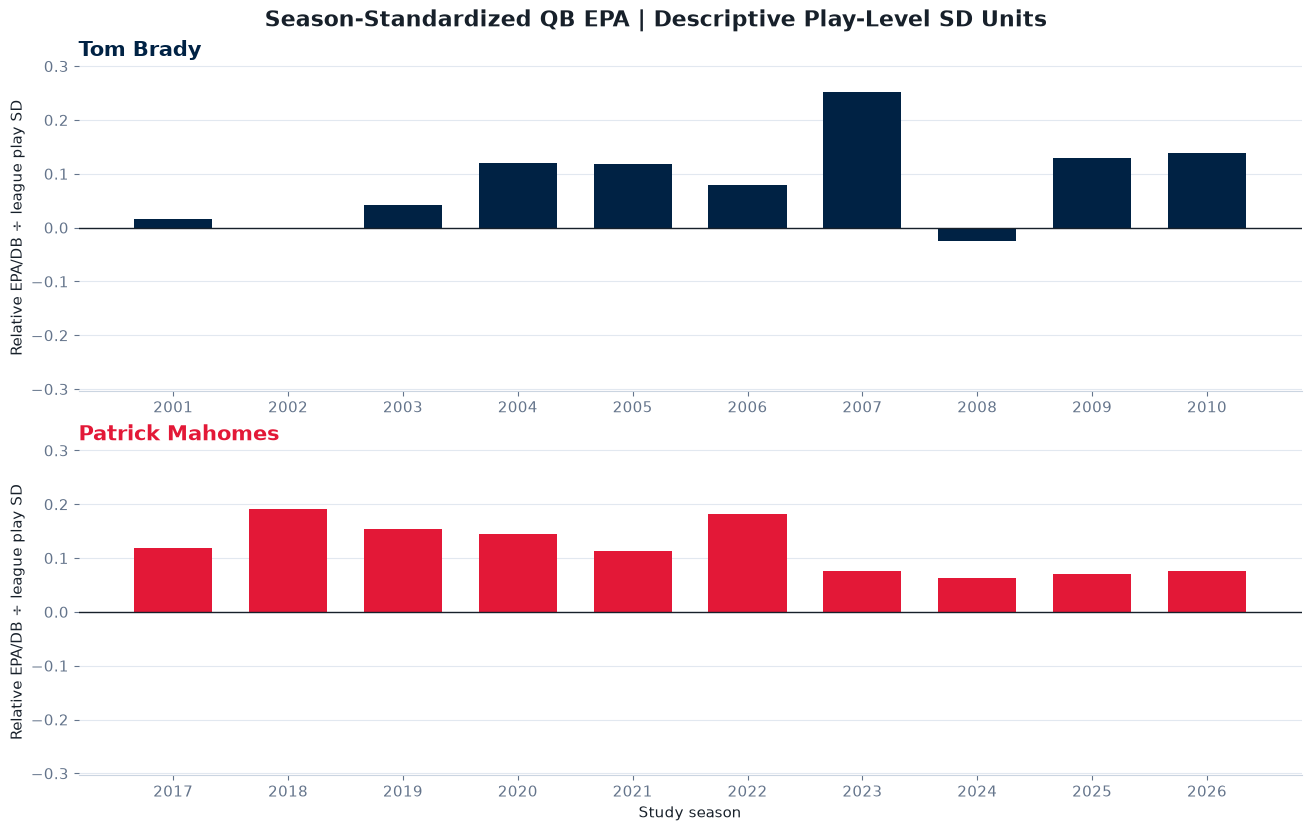

In [19]:
# qb_game_era_adjusted contains the season mean, but not the play-level SD.
normalized_games = games.join(
    league.select("season", "league_qb_epa_std"),
    on="season", how="left", validate="m:1",
)
assert not normalized_games.filter(pl.col("league_qb_epa_std").is_null()).height
normalized_games = normalized_games.with_columns(
    (
        pl.col("relative_qb_epa_per_dropback") / pl.col("league_qb_epa_std")
    ).alias("relative_epa_in_dropback_sd")
)

normalized_seasons = (
    normalized_games.group_by("player_name", "season")
    .agg(
        pl.col("usable_dropbacks").sum().alias("usable_dropbacks"),
        (
            (pl.col("relative_epa_in_dropback_sd") * pl.col("usable_dropbacks")).sum()
            / pl.col("usable_dropbacks").sum()
        ).alias("standardized_relative_epa")
    )
    .sort("player_name", "season")
)
normalized_career = (
    normalized_games.group_by("player_name")
    .agg(
        pl.col("usable_dropbacks").sum().alias("usable_dropbacks"),
        (
            (pl.col("relative_epa_in_dropback_sd") * pl.col("usable_dropbacks")).sum()
            / pl.col("usable_dropbacks").sum()
        ).alias("standardized_relative_epa")
    )
    .sort("player_name")
)

display(normalized_career)

fig, axs = plt.subplots(2, 1, figsize=(13, 8.2), sharey=True, layout="constrained")
normalized_rows = normalized_seasons.to_dicts()
lim = max(0.05, max(abs(float(r["standardized_relative_epa"])) for r in normalized_rows) * 1.20)
for ax, player in zip(axs, ORDER):
    data = sorted((r for r in normalized_rows if r["player_name"] == player),
                  key=lambda r: int(r["season"]))
    xs = np.arange(len(data))
    ys = np.array([float(r["standardized_relative_epa"]) for r in data])
    ax.bar(xs, ys, color=COLORS[player], width=0.68)
    ax.axhline(0, color=INK, linewidth=1)
    ax.set_ylim(-lim, lim)
    ax.set_xticks(xs, [str(r["season"]) for r in data])
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_ylabel("Relative EPA/DB ÷ league play SD")
    ax.set_title(player, color=COLORS[player], weight="bold", loc="left")
    ax.spines[["top", "right", "left"]].set_visible(False)
axs[1].set_xlabel("Study season")
fig.suptitle("Season-Standardized QB EPA | Descriptive Play-Level SD Units",
             fontsize=16, weight="bold")
fig.savefig(FIGURES / "08_season_normalized_qb_epa.png", dpi=220, bbox_inches="tight")
plt.show()

## 8. Relative success rate — a secondary robustness lens

EPA averages can be influenced by a small number of very high- or low-value plays. The **positive-QB-EPA play rate** provides a complementary descriptive perspective. Its era-adjusted version is expressed in **percentage points**, not EPA units.

This rate does **not** replace EPA/DB: it discards information about play magnitude, and a QB can score well on one measure and less well on the other.

In [20]:
summary_rows = {r["player_name"]: r for r in career.to_dicts()}
lines = [
    "| Quarterback | QB EPA/DB | Season-relative EPA/DB | Season-normalized effect | Relative success rate |",
    "|:--|--:|--:|--:|--:|",
]
normalized_lookup = {r["player_name"]: r for r in normalized_career.to_dicts()}
for player in ORDER:
    r = summary_rows[player]
    z = normalized_lookup[player]["standardized_relative_epa"]
    lines.append(
        f"| {player} | {r['qb_epa_per_dropback']:+.4f} | "
        f"{r['relative_qb_epa_per_dropback']:+.4f} | "
        f"{z:+.4f} | {r['relative_qb_epa_success_rate_pp']:+.2f} pp |"
    )
display(Markdown("\n".join(lines)))

| Quarterback | QB EPA/DB | Season-relative EPA/DB | Season-normalized effect | Relative success rate |
|:--|--:|--:|--:|--:|
| Tom Brady | +0.1761 | +0.1542 | +0.0974 | +4.23 pp |
| Patrick Mahomes | +0.2486 | +0.1923 | +0.1230 | +5.86 pp |

## 9. Qualified QB percentile — place each season in the QB distribution

The league baseline is the **dropback-weighted mean of all NFL plays**. A *qualified QB percentile* instead ranks the **QB-season averages of qualifying players**, with each qualified quarterback receiving one rank. These are different questions.

**Qualification (research rule):** at least **200 usable dropbacks** in a full regular season, prorated according to league games available through the 2026 study cutoff. We also audit alternative thresholds of 150 and 250. These are not official NFL eligibility standards.

Percentile is `100 × (N − descending_midrank)/(N − 1)` (higher is better). The best QB has 100; the lowest has 0. It is **not** a play-level z-score, a statistical confidence level, or a claim about causal QB ability.

**Scope warning:** These distributions describe *entire player-seasons*, not necessarily just the player's 131 selected starts. A study-aligned percentile is shown only when total usable dropbacks **and** total EPA match the selected starts. The complete-season percentile is retained and labeled separately when the samples differ (e.g. Brady in 2010).

In [21]:
from matplotlib.lines import Line2D

qualified_path = PROCESSED / "nfl_qualified_qb_season_epa.parquet"
study_pct_path = PROCESSED / "study_qb_qualified_percentiles.parquet"
sensitivity_path = ROOT / "reports/validation/qualified_qb_threshold_sensitivity.csv"
for p in (qualified_path, study_pct_path, sensitivity_path):
    if not p.is_file():
        raise FileNotFoundError(
            f"Missing {p}. First run: python3 scripts/build_qualified_qb_percentiles.py"
        )

qualified = pl.read_parquet(qualified_path)
study_pct = pl.read_parquet(study_pct_path)
sensitivity = pl.read_csv(sensitivity_path)
assert study_pct.height == 20
assert qualified['season'].n_unique() == 20
assert qualified.select(pl.struct('season', 'player_id').n_unique()).item() == qualified.height
assert not qualified.filter(pl.col('qualified_qb_percentile').is_null()).height
assert not qualified.filter((pl.col('qualified_qb_percentile') < 0) | (pl.col('qualified_qb_percentile') > 100)).height

lines = [
    '| QB | Season | Qualifying QBs | Rank | Full-season percentile | Study-aligned percentile | Sample status |',
    '|:--|--:|--:|--:|--:|--:|:--|',
]
for row in study_pct.sort('player_name', 'season').to_dicts():
    pct = row['qualified_qb_percentile']
    aligned = row['study_aligned_qualified_percentile']
    rank = row['rank_descending']
    lines.append(
        f"| {row['player_name']} | {row['season']} | "
        f"{row['qualified_qb_count'] if row['qualified_qb_count'] is not None else '—'} | "
        f"{f'{rank:.1f}' if rank is not None else '—'} | "
        f"{f'{pct:.1f}' if pct is not None else 'N/Q'} | "
        f"{f'{aligned:.1f}' if aligned is not None else 'N/A'} | "
        f"{row['interpretation_status']} |"
    )

display(Markdown('\n'.join(lines)))
print(f"Qualified QB-season observations: {qualified.height}")
print('Strictly study-aligned qualified seasons:',
      study_pct.filter(pl.col('study_aligned_qualified_percentile').is_not_null()).height)


| QB | Season | Qualifying QBs | Rank | Full-season percentile | Study-aligned percentile | Sample status |
|:--|--:|--:|--:|--:|--:|:--|
| Patrick Mahomes | 2017 | — | — | N/Q | N/A | NOT_QUALIFIED |
| Patrick Mahomes | 2018 | 36 | 1.0 | 100.0 | 100.0 | STUDY_ALIGNED |
| Patrick Mahomes | 2019 | 34 | 2.0 | 97.0 | 97.0 | STUDY_ALIGNED |
| Patrick Mahomes | 2020 | 36 | 2.0 | 97.1 | 97.1 | STUDY_ALIGNED |
| Patrick Mahomes | 2021 | 35 | 2.0 | 97.1 | 97.1 | STUDY_ALIGNED |
| Patrick Mahomes | 2022 | 35 | 1.0 | 100.0 | 100.0 | STUDY_ALIGNED |
| Patrick Mahomes | 2023 | 39 | 6.0 | 86.8 | 86.8 | STUDY_ALIGNED |
| Patrick Mahomes | 2024 | 40 | 10.0 | 76.9 | 76.9 | STUDY_ALIGNED |
| Patrick Mahomes | 2025 | 38 | 9.0 | 78.4 | 78.4 | STUDY_ALIGNED |
| Patrick Mahomes | 2026 | 35 | 11.0 | 70.6 | 70.6 | STUDY_ALIGNED |
| Tom Brady | 2001 | 31 | 14.0 | 56.7 | N/A | FULL_SEASON_INCLUDES_NON_STUDY_PLAYS |
| Tom Brady | 2002 | 36 | 21.0 | 42.9 | 42.9 | STUDY_ALIGNED |
| Tom Brady | 2003 | 38 | 13.0 | 67.6 | 67.6 | STUDY_ALIGNED |
| Tom Brady | 2004 | 36 | 7.0 | 82.9 | 82.9 | STUDY_ALIGNED |
| Tom Brady | 2005 | 37 | 5.0 | 88.9 | 88.9 | STUDY_ALIGNED |
| Tom Brady | 2006 | 37 | 6.0 | 86.1 | 86.1 | STUDY_ALIGNED |
| Tom Brady | 2007 | 38 | 1.0 | 100.0 | 100.0 | STUDY_ALIGNED |
| Tom Brady | 2008 | — | — | N/Q | N/A | NOT_QUALIFIED |
| Tom Brady | 2009 | 34 | 5.0 | 87.9 | 87.9 | STUDY_ALIGNED |
| Tom Brady | 2010 | 34 | 1.0 | 100.0 | N/A | FULL_SEASON_INCLUDES_NON_STUDY_PLAYS |

Qualified QB-season observations: 719
Strictly study-aligned qualified seasons: 16


### Figure 6 — Seasonal distributions of qualified QB EPA/dropback

Each gray point is one **qualified QB's season average EPA/dropback**, not an individual play. Colored points identify the research QB's *full-season* EPA/DB. Filled markers match the study-start population; hollow diamonds use a wider season population. Years without a qualified research QB have no colored marker.

**Read the vertical position as absolute QB EPA/DB; the percentile of that QB is shown separately below.** Gray points make it possible to judge whether the season was tightly packed or had a few very strong outliers.

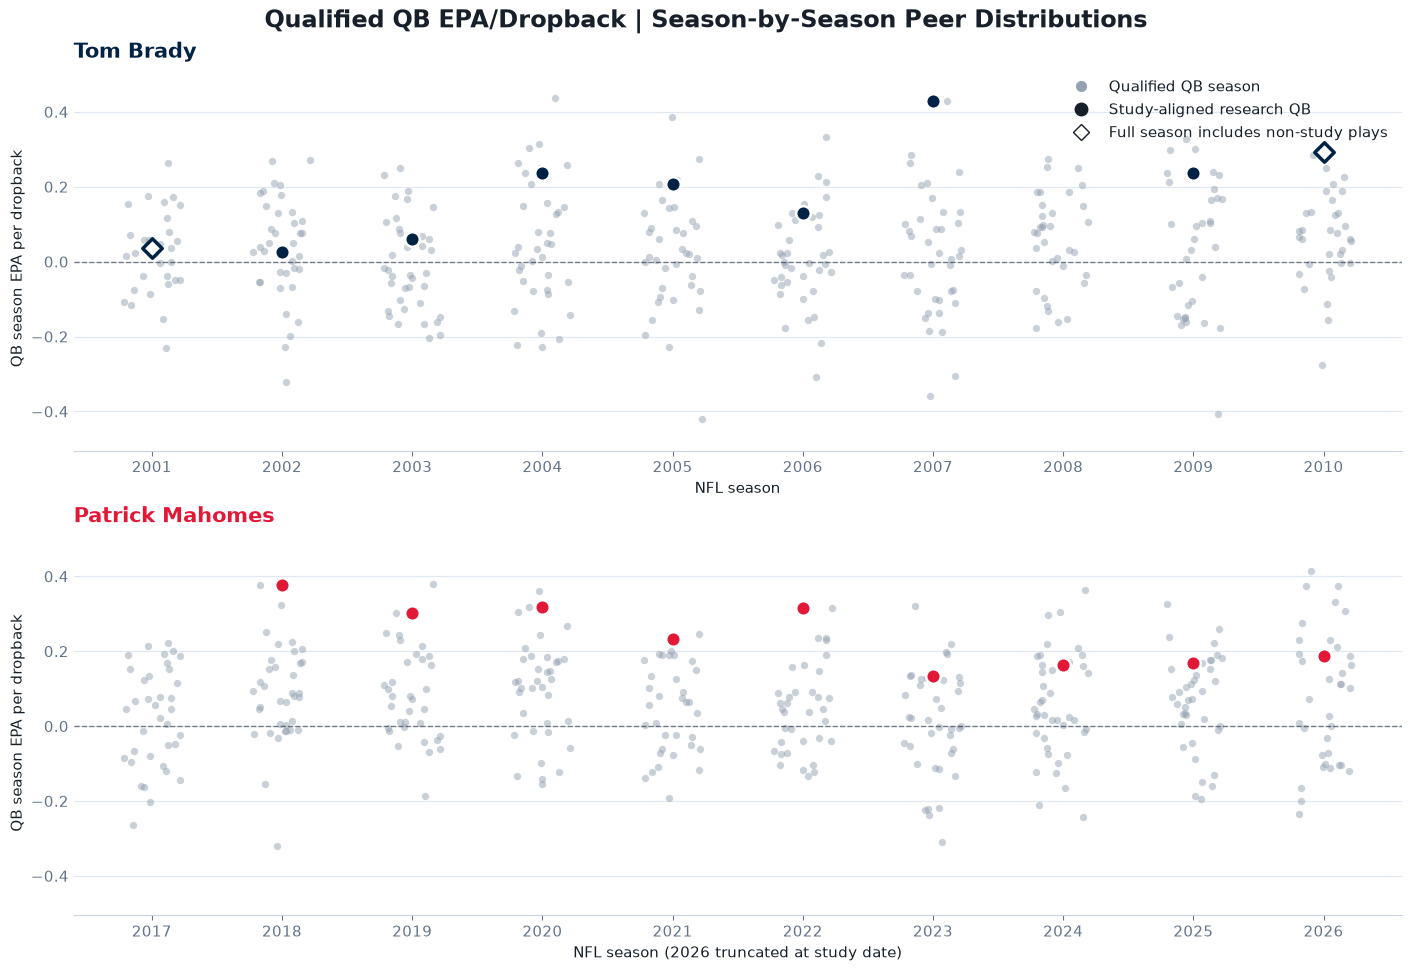

In [22]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9.6), layout='constrained', sharey=True)
all_epa = qualified['qb_epa_per_dropback'].to_numpy()
y_low, y_high = float(np.min(all_epa)), float(np.max(all_epa))
pad = max((y_high - y_low) * 0.10, 0.045)

for ax, player in zip(axes, ORDER):
    years = list(range(2001, 2011)) if player == 'Tom Brady' else list(range(2017, 2027))
    rng = np.random.default_rng(42)  # Deterministic visual jitter; no data changes.
    for yr in years:
        group = qualified.filter(pl.col('season') == yr)
        values = group['qb_epa_per_dropback'].to_numpy()
        xs = yr + rng.uniform(-0.23, 0.23, size=len(values))
        ax.scatter(xs, values, s=28, color='#95A2B3', alpha=0.5,
                   zorder=2, linewidths=0)
    focus = study_pct.filter(pl.col('player_name') == player).sort('season').to_dicts()
    for row in focus:
        if not row['qualified']:
            continue
        x, y = int(row['season']), float(row['fullseason_qb_epa_per_dropback'])
        if row['fullseason_matches_study_starts']:
            ax.scatter(x, y, color=COLORS[player], s=110, edgecolor='white',
                       linewidth=1.8, zorder=5)
        else:
            ax.scatter(x, y, facecolors='white', edgecolors=COLORS[player], marker='D',
                       s=98, linewidth=2.5, zorder=6)
    ax.set_xticks(years)
    ax.set_xlim(min(years)-0.6, max(years)+0.6)
    ax.set_ylim(y_low-pad, y_high+pad)
    ax.axhline(0, color=INK, linewidth=1, linestyle='--', alpha=0.55)
    ax.grid(axis='y', color=GRID, linewidth=0.9)
    ax.set_axisbelow(True)
    ax.set_ylabel('QB season EPA per dropback')
    ax.set_title(player, loc='left', color=COLORS[player], fontweight='bold')
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.set_xlabel('NFL season (2026 truncated at study date)' if player == 'Patrick Mahomes'
                  else 'NFL season')

legend = [
    Line2D([0], [0], linestyle='', marker='o', markerfacecolor='#95A2B3',
           markeredgecolor='none', markersize=8, label='Qualified QB season'),
    Line2D([0], [0], linestyle='', marker='o', color=INK, markersize=9,
           label='Study-aligned research QB'),
    Line2D([0], [0], linestyle='', marker='D', markerfacecolor='white',
           markeredgecolor=INK, markersize=8, label='Full season includes non-study plays'),
]
axes[0].legend(handles=legend, frameon=False, loc='upper right', ncol=1)
fig.suptitle('Qualified QB EPA/Dropback | Season-by-Season Peer Distributions',
             fontsize=17, weight='bold')
fig.savefig(FIGURES / '09_qualified_qb_season_distributions.png',
            dpi=240, bbox_inches='tight')
plt.show()


### Figure 7 — Percentile trajectory within qualified QB peer groups

A percentile near 90 means the QB ranked above roughly 90% of that season's qualifying QBs under the stated rank definition. **It does not mean 90% more EPA, nor a 90% likelihood of being the best player.**

- **Filled circle:** the full-season QB dropbacks are identical to the study subset, so the ranking can also describe the selected starts.
- **Hollow diamond:** the full-season QB percentile includes plays *outside* the selected 131 starts. It is **context only**, not a study-start percentile.
- **N/Q:** not qualified; no percentile is assigned. Neither a one-game start nor a small sample should be stretched into a season-long ranking.
- **2026:** provisional peer group through the study date, with a prorated cutoff.

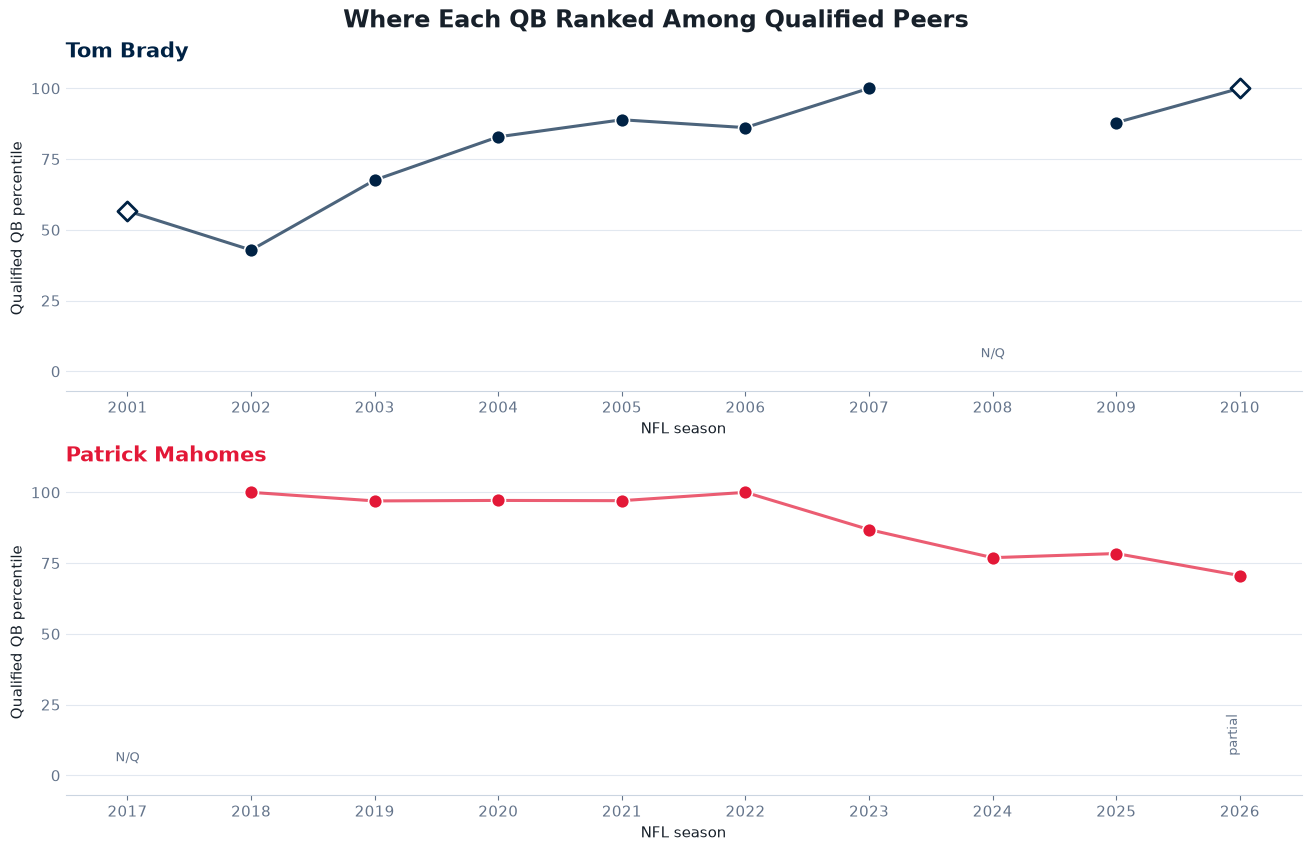

Sensitivity of study QB full-season percentiles to qualification cutoffs:


season,player_id,player_name,150,200,250
i64,str,str,f64,f64,f64
2018,"""00-0033873""","""Patrick Mahomes""",100.0,100.0,100.0
2019,"""00-0033873""","""Patrick Mahomes""",97.368421,96.969697,96.774194
2020,"""00-0033873""","""Patrick Mahomes""",97.5,97.142857,97.058824
2021,"""00-0033873""","""Patrick Mahomes""",97.368421,97.058824,96.875
2022,"""00-0033873""","""Patrick Mahomes""",100.0,100.0,100.0
…,…,…,…,…,…
2005,"""00-0019596""","""Tom Brady""",90.47619,88.888889,87.878788
2006,"""00-0019596""","""Tom Brady""",87.804878,86.111111,83.870968
2007,"""00-0019596""","""Tom Brady""",100.0,100.0,100.0


In [23]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8.4), layout='constrained', sharey=True)
for ax, player in zip(axes, ORDER):
    focus = study_pct.filter(pl.col('player_name') == player).sort('season').to_dicts()
    years = [int(r['season']) for r in focus]
    pcts = [float(r['qualified_qb_percentile']) if r['qualified_qb_percentile'] is not None
            else np.nan for r in focus]
    ax.plot(years, pcts, color=COLORS[player], linewidth=2.2, alpha=0.7)
    for r in focus:
        x = int(r['season'])
        value = r['qualified_qb_percentile']
        if value is None:
            ax.text(x, 5, 'N/Q', ha='center', fontsize=9, color=SUBTLE)
        elif r['fullseason_matches_study_starts']:
            ax.scatter(x, float(value), s=100, c=COLORS[player],
                       edgecolors='white', linewidths=1.2, zorder=5)
        else:
            ax.scatter(x, float(value), s=95, facecolors='white',
                       edgecolors=COLORS[player], marker='D', linewidths=2, zorder=6)
        if x == 2026:
            ax.text(x, 8, 'partial', ha='right', fontsize=9, color=SUBTLE, rotation=90)
    ax.set_ylim(-7, 108)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_xticks(years)
    ax.set_xlim(min(years)-0.5, max(years)+0.5)
    ax.grid(axis='y', color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_title(player, loc='left', color=COLORS[player], weight='bold')
    ax.set_ylabel('Qualified QB percentile')
    ax.set_xlabel('NFL season')
    ax.spines[['top','right','left']].set_visible(False)
    ax.tick_params(axis='y', length=0)
fig.suptitle('Where Each QB Ranked Among Qualified Peers', fontsize=17, weight='bold')
fig.savefig(FIGURES / '10_qualified_qb_percentiles.png',
            dpi=240, bbox_inches='tight')
plt.show()

# Sensitivity check: how far does each QB full-season percentile move when
# the qualification rule changes from 200 to 150 or 250 season dropbacks?
study_ids = study_pct.select('season', 'player_id', 'player_name')
sens_study = sensitivity.join(study_ids, on=['season', 'player_id'], how='inner')
sens_wide = sens_study.pivot(
    index=['season', 'player_id', 'player_name'],
    on='threshold_full_season',
    values='qualified_qb_percentile',
).sort('player_name', 'season')
print('Sensitivity of study QB full-season percentiles to qualification cutoffs:')
display(sens_wide)


### Qualified QB percentile table — season-by-season comparison

This compact table accompanies Figures 6 and 7. **Exact percentiles** are loaded from the validated `study_qb_qualified_percentiles.parquet` file; none are copied from a chart or rounded by eye.

Each column follows the player's own NFL seasons chronologically, rather than matching calendar years. The research uses the **full-season qualified-QB peer ranking**; years whose QB data include plays outside our selected starts are marked explicitly. Percentile 100 means the best-ranked qualified QB, not perfect performance.

In [24]:
# Compare qualified QB percentiles side by side using exact season data.
# The percentages come from the processed percentile table, not chart estimates.
percentiles_by_qb = {
    player: (
        study_pct.filter(pl.col("player_name") == player)
        .sort("season")
        .to_dicts()
    )
    for player in ORDER
}

# Both players cover ten distinct NFL seasons in the research timeline.
assert [r["season"] for r in percentiles_by_qb["Tom Brady"]] == list(range(2001, 2011))
assert [r["season"] for r in percentiles_by_qb["Patrick Mahomes"]] == list(range(2017, 2027))


def format_season_percentile(row):
    """Display the year, exact computed percentile, and sample-scope markers."""
    pct = row["qualified_qb_percentile"]
    result = "N/Q" if pct is None else f"{pct:.1f}%"
    if pct is not None and not row["fullseason_matches_study_starts"]:
        result += "†"  # A full-season rank includes non-study QB plays.
    if int(row["season"]) == 2026:
        result += "‡"  # Partial NFL season through the study cutoff date.
    return f"**{int(row['season'])}** · {result}"

brady_rows = percentiles_by_qb["Tom Brady"]
mahomes_rows = percentiles_by_qb["Patrick Mahomes"]

percentile_table = [
    "| Tom Brady | Patrick Mahomes |",
    "|:--|:--|",
]
for brady, mahomes in zip(brady_rows, mahomes_rows):
    percentile_table.append(
        f"| {format_season_percentile(brady)} | "
        f"{format_season_percentile(mahomes)} |"
    )

percentile_table.extend([
    "",
    "**N/Q:** Does not meet the study's minimum qualifying dropbacks; no percentile is assigned.",
    "**†:** The full-season percentile includes dropbacks outside the 131 selected starts; use as seasonal context, not as a study-only rank.",
    "**‡:** The 2026 percentile is provisional, based on league data through October 18, 2026 and a prorated qualification threshold.",
    "Percentiles use the 200-dropback research threshold (prorated in 2026), "
    "with midrank treatment for ties; higher is better.",
])

display(Markdown("\n".join(percentile_table)))

| Tom Brady | Patrick Mahomes |
|:--|:--|
| **2001** · 56.7%† | **2017** · N/Q |
| **2002** · 42.9% | **2018** · 100.0% |
| **2003** · 67.6% | **2019** · 97.0% |
| **2004** · 82.9% | **2020** · 97.1% |
| **2005** · 88.9% | **2021** · 97.1% |
| **2006** · 86.1% | **2022** · 100.0% |
| **2007** · 100.0% | **2023** · 86.8% |
| **2008** · N/Q | **2024** · 76.9% |
| **2009** · 87.9% | **2025** · 78.4% |
| **2010** · 100.0%† | **2026** · 70.6%‡ |

**N/Q:** Does not meet the study's minimum qualifying dropbacks; no percentile is assigned.
**†:** The full-season percentile includes dropbacks outside the 131 selected starts; use as seasonal context, not as a study-only rank.
**‡:** The 2026 percentile is provisional, based on league data through October 18, 2026 and a prorated qualification threshold.
Percentiles use the 200-dropback research threshold (prorated in 2026), with midrank treatment for ties; higher is better.

### Qualification-threshold sensitivity — 150 / 200 / 250 dropbacks

The percentile depends on the qualifying-QB peer group. To test robustness, recompute Brady's and Mahomes's **full-season** percentiles with minimum qualification thresholds of **150, 200, and 250 usable dropbacks** (the main analysis uses 200). For partial 2026, all thresholds are prorated according to the number of NFL games included by the study cutoff.

A season can be **N/Q** at one cutoff but qualified at another. We do not treat N/Q as zero. **Range (pp)** is the largest minus the smallest percentile in percentage points, calculated only when the QB qualifies at **all three** cutoffs. A small range indicates stability *to this particular selection rule*, not statistical certainty. Percentiles marked as including non-study plays and those for partial 2026 retain the same scope limitations noted above.

The cell displays the comparison and exports an auditable study-player report to `reports/validation/qualified_qb_sensitivity_summary.csv`. It does not modify the validated EPA datasets.

In [25]:
# Summarize the three qualification rules for the two study quarterbacks.
# The long-form source file was already generated by build_qualified_qb_percentiles.py.
# Run the notebook from the beginning so study_pct and sensitivity are loaded.
THRESHOLDS = (150, 200, 250)

sensitivity_lookup = {
    (int(r["season"]), str(r["player_id"]), int(r["threshold_full_season"])): r
    for r in sensitivity.to_dicts()
}

report_rows = []
for player in ORDER:
    for qb in study_pct.filter(pl.col("player_name") == player).sort("season").to_dicts():
        year, qb_id = int(qb["season"]), str(qb["player_id"])
        record = {
            "player_name": player,
            "season": year,
            "sample_status": qb["interpretation_status"],
        }
        percentiles = []
        for threshold in THRESHOLDS:
            match = sensitivity_lookup.get((year, qb_id, threshold))
            pct = float(match["qualified_qb_percentile"]) if match is not None else None
            record[f"percentile_{threshold}"] = pct
            record[f"peers_{threshold}"] = int(match["qualified_qb_count"]) if match is not None else None
            record[f"effective_min_{threshold}"] = int(match["threshold_effective"]) if match is not None else None
            if pct is not None:
                percentiles.append(pct)
        record["qualified_all_three"] = len(percentiles) == len(THRESHOLDS)
        record["percentile_range_pp"] = (
            max(percentiles) - min(percentiles)
            if record["qualified_all_three"] else None
        )
        report_rows.append(record)

assert len(report_rows) == 20, "Expected exactly 20 study QB-season records"

# Guardrail: the 200-DB column must reproduce the main validated results.
for record in report_rows:
    original = study_pct.filter(
        (pl.col("player_name") == record["player_name"])
        & (pl.col("season") == record["season"])
    ).row(0, named=True)["qualified_qb_percentile"]
    new = record["percentile_200"]
    assert (original is None and new is None) or (
        original is not None and new is not None and abs(float(original) - new) < 1e-9
    ), f"200-DB reference mismatch for {record['player_name']} {record['season']}"

sensitivity_report = pl.DataFrame(report_rows, infer_schema_length=None)
report_path = ROOT / "reports" / "validation" / "qualified_qb_sensitivity_summary.csv"
report_path.parent.mkdir(parents=True, exist_ok=True)
sensitivity_report.write_csv(report_path)

def show_pct(value):
    return "N/Q" if value is None else f"{value:.1f}%"

lines = [
    "| Quarterback | Season | Min 150 | Min 200 | Min 250 | Range (pp) |",
    "|:--|--:|--:|--:|--:|--:|",
]
for row in report_rows:
    span = row["percentile_range_pp"]
    lines.append(
        f"| {row['player_name']} | {row['season']} | "
        f"{show_pct(row['percentile_150'])} | {show_pct(row['percentile_200'])} | "
        f"{show_pct(row['percentile_250'])} | "
        f"{'N/A' if span is None else f'{span:.1f}'} |"
    )
display(Markdown("\n".join(lines)))

comparable = [r for r in report_rows if r["qualified_all_three"]]
changed_qualification = [
    r for r in report_rows
    if 0 < sum(r[f"percentile_{t}"] is not None for t in THRESHOLDS) < 3
]
if comparable:
    top_changes = sorted(comparable, key=lambda r: r["percentile_range_pp"], reverse=True)
    largest = top_changes[0]
    print(f"Comparable seasons: {len(comparable)}/20")
    print(f"Largest range: {largest['player_name']} {largest['season']} — "
          f"{largest['percentile_range_pp']:.2f} percentage points")
    print(f"Mean range: {sum(r['percentile_range_pp'] for r in comparable) / len(comparable):.2f} pp")
print(f"Qualification-status changes across thresholds: {len(changed_qualification)}")
for r in changed_qualification:
    print(f"  {r['player_name']} {r['season']}: " + ", ".join(
        f"{t}={show_pct(r[f'percentile_{t}'])}" for t in THRESHOLDS
    ))
print(f"Saved study-player sensitivity report: {report_path}")


| Quarterback | Season | Min 150 | Min 200 | Min 250 | Range (pp) |
|:--|--:|--:|--:|--:|--:|
| Tom Brady | 2001 | 61.8% | 56.7% | 56.7% | 5.1 |
| Tom Brady | 2002 | 50.0% | 42.9% | 38.7% | 11.3 |
| Tom Brady | 2003 | 66.7% | 67.6% | 61.3% | 6.3 |
| Tom Brady | 2004 | 83.8% | 82.9% | 80.6% | 3.1 |
| Tom Brady | 2005 | 90.5% | 88.9% | 87.9% | 2.6 |
| Tom Brady | 2006 | 87.8% | 86.1% | 83.9% | 3.9 |
| Tom Brady | 2007 | 100.0% | 100.0% | 100.0% | 0.0 |
| Tom Brady | 2008 | N/Q | N/Q | N/Q | N/A |
| Tom Brady | 2009 | 89.7% | 87.9% | 87.1% | 2.6 |
| Tom Brady | 2010 | 100.0% | 100.0% | 100.0% | 0.0 |
| Patrick Mahomes | 2017 | N/Q | N/Q | N/Q | N/A |
| Patrick Mahomes | 2018 | 100.0% | 100.0% | 100.0% | 0.0 |
| Patrick Mahomes | 2019 | 97.4% | 97.0% | 96.8% | 0.6 |
| Patrick Mahomes | 2020 | 97.5% | 97.1% | 97.1% | 0.4 |
| Patrick Mahomes | 2021 | 97.4% | 97.1% | 96.9% | 0.5 |
| Patrick Mahomes | 2022 | 100.0% | 100.0% | 100.0% | 0.0 |
| Patrick Mahomes | 2023 | 88.6% | 86.8% | 84.4% | 4.3 |
| Patrick Mahomes | 2024 | 79.1% | 76.9% | 75.7% | 3.4 |
| Patrick Mahomes | 2025 | 81.0% | 78.4% | 77.1% | 3.8 |
| Patrick Mahomes | 2026 | 70.3% | 70.6% | 69.7% | 0.9 |

Comparable seasons: 18/20
Largest range: Tom Brady 2002 — 11.29 percentage points
Mean range: 2.71 pp
Qualification-status changes across thresholds: 0
Saved study-player sensitivity report: /home/lucas/2110/mahomes-brady/reports/validation/qualified_qb_sensitivity_summary.csv


## 10. Findings and limitations — complete only after executing the notebook

### Findings to report (fill from observed results)

1. **NFL environment.** Report the historical ranges and any clear departures from a monotonic passing-era narrative (Figure 1).
2. **131-start comparison.** State each QB's *dropback-weighted* absolute and relative EPA/DB, including the observed difference (Figure 2).
3. **Season variation.** Identify robust multi-start seasons separately from unusually high/low one-start season segments (Figure 3).
4. **Career development.** Describe differences between cumulative and trailing 16-start trajectories (Figure 4).
5. **Robustness.** Explain whether play-SD standardized results and relative positive-EPA rates tell a similar story (Figure 5 and Section 8).
6. **Qualified QB peer ranking.** Compare each QB to the qualified player-season distribution and report non-qualifying or non-study-aligned years explicitly (Figures 6–7 and the percentile table).

### Limitations

- **Not causal.** QB EPA incorporates team context, offensive scheme, opponents, game state, and model assumptions; it does not isolate quarterback talent.
- **League reference is play-weighted.** League baselines include dropbacks by Brady/Mahomes themselves. Comparison to an equally weighted *qualified-QB cohort* requires a separate calculation.
- **Sample segmentation matters.** The study contains exactly the selected 131 starts per QB, not necessarily all games or all starts within each displayed NFL season. Brady 2008 and Mahomes 2017 have only one study start.
- **2026 is partial.** The 2026 NFL baseline is cut off at **2026-10-18** and may change when more games are available. It should not be compared as though it represented a finished season.
- **Scramble restoration.** The source's historical `qb_scramble` tags were used to restore missing dropbacks, particularly in 2001–2005. No untagged QB rushing plays were assumed to be scrambles.
- **Known missing EPA.** One nonstudy-player play (`2019_01_PIT_NE`, play 4166) lacks QB EPA and was omitted from the corresponding NFL baseline; zero was never imputed.
- **No uncertainty intervals yet.** These are descriptive differences for fixed historical samples. We have not modeled game clustering, strength of schedule, or uncertainty and should avoid significance claims.
- **Standardization is not ranking.** Dividing by the league **play-level** standard deviation yields an effect scale, not a QB percentile, QB-rank z-score, or proof of statistical significance.
- **Peer-percentile scope.** Qualified-QB percentiles refer to full player-seasons (2026 is truncated). They can include QB plays outside the selected 131 starts, and depend on the chosen qualification threshold.

### Next methodological extensions

- **Three-year relative QB EPA/DB:** define a trailing or centered window with enough neighboring years, document how era boundaries and 2026 are handled, and use a dropback-weighted league baseline.
- **Sensitivity analysis:** repeat the main comparison with alternative baselines (qualified QB reference, leave-study-QB-out league baseline, and context-adjusted models where justified).

**Research framing:** which QB produced the stronger *observed era-relative performance* across these starts? This notebook helps answer that narrower question, rather than treating EPA as a definitive GOAT ranking.

## 11. Outputs and reproducibility

Figures written automatically to `reports/figures/`:

- `04_nfl_era_baselines.png`
- `05_qb_vs_era_baseline_131.png`
- `06_season_relative_qb_epa.png`
- `07_era_relative_career_evolution.png`
- `08_season_normalized_qb_epa.png`

Existing validated tables under `data/processed/` are never overwritten. To regenerate plots, rerun this notebook from the first cell after rebuilding its upstream processed tables. The narrative findings above deliberately contain no invented values and should be finalized only after inspecting real outputs.

**Data provenance:** `docs/era_adjustment_baseline_decisions.md` and `docs/era_adjusted_qb_methodology.md`.

Additional figures (after running the qualified-QB ranking pipeline):

- `09_qualified_qb_season_distributions.png`
- `10_qualified_qb_percentiles.png`


The **qualified QB percentile comparison table** appears beneath Figure 7 and is generated directly from `data/processed/study_qb_qualified_percentiles.parquet` on each execution.


The **qualification-threshold sensitivity summary** appears after the percentile table and writes `reports/validation/qualified_qb_sensitivity_summary.csv` when executed. The raw all-QB report remains `reports/validation/qualified_qb_threshold_sensitivity.csv`.
